In [22]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models

(X_train, y_train), (X_test, y_test) = tf.keras.datasets.mnist.load_data()

X_train = X_train.reshape(-1, 28, 28, 1).astype("float32") / 255.0
X_test = X_test.reshape(-1, 28, 28, 1).astype("float32") / 255.0

model = models.Sequential(
    [
        layers.Input(shape=(28, 28, 1)),
        layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(128, (3, 3), activation="relu"),
        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(10, activation="softmax"),
    ]
)

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_data=(X_test, y_test),
)

Epoch 1/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 10s 10ms/step - accuracy: 0.9618 - loss: 0.1295 - val_accuracy: 0.9862 - val_loss: 0.0412
Epoch 2/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - accuracy: 0.9860 - loss: 0.0476 - val_accuracy: 0.9900 - val_loss: 0.0309
Epoch 3/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - accuracy: 0.9890 - loss: 0.0371 - val_accuracy: 0.9913 - val_loss: 0.0317
Epoch 4/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - accuracy: 0.9913 - loss: 0.0298 - val_accuracy: 0.9926 - val_loss: 0.0326
Epoch 5/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - accuracy: 0.9929 - loss: 0.0237 - val_accuracy: 0.9833 - val_loss: 0.0669


test1.png -> 1 (99.7%)
test2.png -> 2 (100.0%)
test3.png -> 3 (100.0%)
test4.png -> 7 (100.0%)
test5.png -> 1 (55.9%)
test6.png -> 6 (81.8%)
test7.png -> 5 (85.0%)


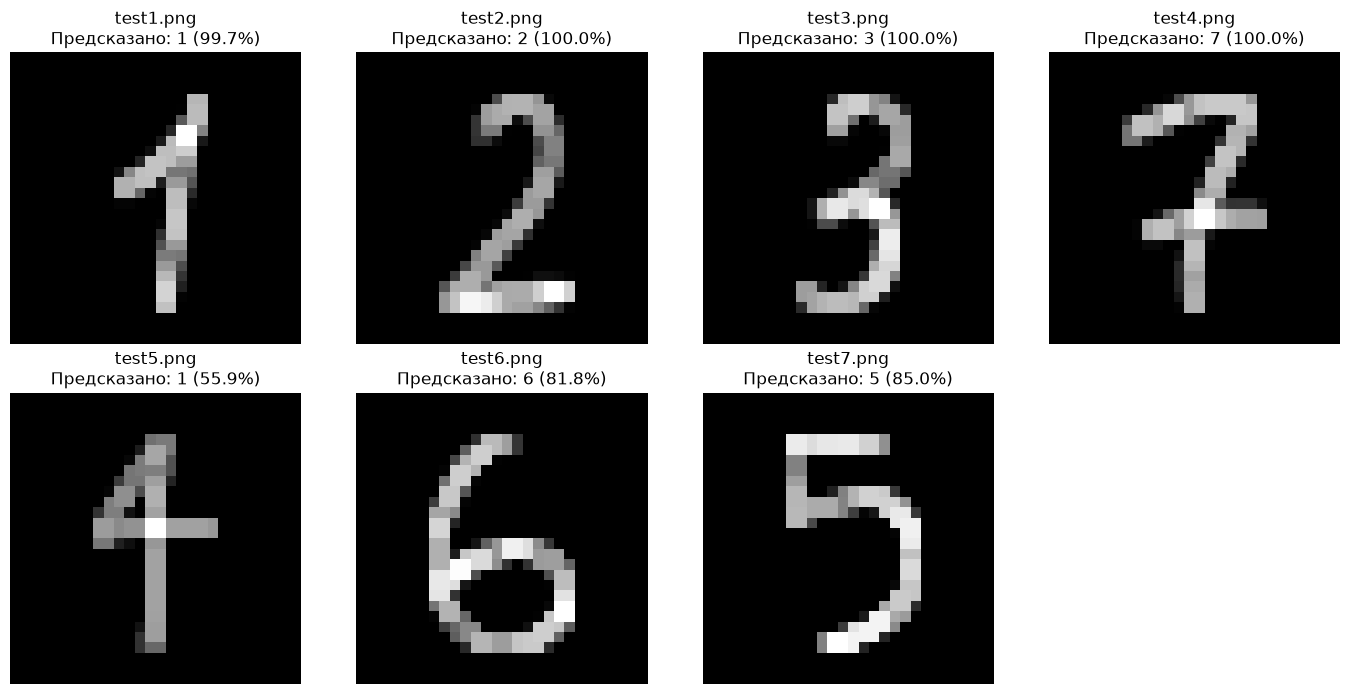

In [ ]:
import os
import cv2
import matplotlib.pyplot as plt
import numpy as np

folder_name = "test_digits"
valid_exts = (".png", ".jpg", ".jpeg", ".bmp", ".webp")

image_files = sorted(
    [f for f in os.listdir(folder_name) if f.lower().endswith(valid_exts)]
)


def smart_preprocess(file_path):
    img = cv2.imread(file_path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        return None

    if np.mean(img) > 127:
        img = cv2.bitwise_not(img)

    _, thresh = cv2.threshold(
        img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    contours, _ = cv2.findContours(
        thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    
    if not contours:
        return None

    c = max(contours, key=cv2.contourArea)
    x, y, w, h = cv2.boundingRect(c)
    digit = thresh[y : y + h, x : x + w]

    if h > w:
        new_h = 20
        new_w = max(1, int(w * (20.0 / h)))
    else:
        new_w = 20
        new_h = max(1, int(h * (20.0 / w)))

    digit_resized = cv2.resize(
        digit, (new_w, new_h), interpolation=cv2.INTER_AREA)

    canvas = np.zeros((28, 28), dtype=np.uint8)
    start_y = (28 - new_h) // 2
    start_x = (28 - new_w) // 2
    canvas[start_y : start_y + new_h, start_x : start_x + new_w] = (
        digit_resized
    )

    kernel = np.ones((2, 2), np.uint8)
    canvas = cv2.dilate(canvas, kernel, iterations=1)

    return canvas.astype("float32") / 255.0


if image_files:
    cols = 4
    rows = (len(image_files) + cols - 1) // cols
    plt.figure(figsize=(cols * 3.5, rows * 3.5))

    for idx, filename in enumerate(image_files):
        path = os.path.join(folder_name, filename)
        processed = smart_preprocess(path)

        if processed is None:
            continue

        input_data = processed.reshape(1, 28, 28, 1)
        preds = model.predict(input_data, verbose=0)
        digit = np.argmax(preds)
        conf = np.max(preds) * 100

        print(f"{filename} -> {digit} ({conf:.1f}%)")

        plt.subplot(rows, cols, idx + 1)
        plt.imshow(processed, cmap="gray")
        plt.title(f"{filename}\nПредсказано: {digit} ({conf:.1f}%)")
        plt.axis("off")

    plt.tight_layout()
    plt.show()